In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import Sequential

In [ ]:
data = load_breast_cancer()

In [ ]:
data

{'data': array([[1.799e+01, 1.038e+01, 1.228e+02, ..., 2.654e-01, 4.601e-01,
         1.189e-01],
        [2.057e+01, 1.777e+01, 1.329e+02, ..., 1.860e-01, 2.750e-01,
         8.902e-02],
        [1.969e+01, 2.125e+01, 1.300e+02, ..., 2.430e-01, 3.613e-01,
         8.758e-02],
        ...,
        [1.660e+01, 2.808e+01, 1.083e+02, ..., 1.418e-01, 2.218e-01,
         7.820e-02],
        [2.060e+01, 2.933e+01, 1.401e+02, ..., 2.650e-01, 4.087e-01,
         1.240e-01],
        [7.760e+00, 2.454e+01, 4.792e+01, ..., 0.000e+00, 2.871e-01,
         7.039e-02]]),
 'target': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
        0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
        1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0,
        1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1,
        1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0

In [ ]:
x, y = data.data, data.target

In [ ]:
# split the data and standardize

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y,
                                                    random_state= 42,
                                                    test_size = 0.25)

In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
sca = StandardScaler()
x_train = sca.fit_transform(x_train)
x_test = sca.transform(x_test)

In [ ]:
x_train.shape

(426, 30)

In [ ]:
# initialize the model

In [ ]:
x_train.shape[1]

30

In [ ]:
model = Sequential()

In [ ]:
model.add(Dense(64, activation = 'relu',
                input_shape = (30,)))
model.add(Dense(32, activation = 'relu'))
model.add(Dense(1, activation = 'sigmoid'))

In [ ]:
# compile

model.compile(optimizer = 'adam',
              loss = 'binary_crossentropy',
              metrics = ['accuracy'])

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,097 (16.00 KB)

 Trainable params: 4,097 (16.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(x_train, y_train, epochs = 100,
                    validation_split = 0.2,
                    batch_size = 32)

Epoch 1/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 192ms/step - accuracy: 0.6324 - loss: 0.6932 - val_accuracy: 0.8256 - val_loss: 0.5133
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9118 - loss: 0.4135 - val_accuracy: 0.9302 - val_loss: 0.3107
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9353 - loss: 0.2770 - val_accuracy: 0.9651 - val_loss: 0.2077
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9441 - loss: 0.2002 - val_accuracy: 0.9767 - val_loss: 0.1560
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9500 - loss: 0.1558 - val_accuracy: 0.9767 - val_loss: 0.1262
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9618 - loss: 0.1314 - val_accuracy: 0.9767 - val_loss: 0.1074
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9735 - loss: 0.1105 - val_accuracy: 0.9767 - val_loss: 0.0987
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9765 - loss: 0.0973 - val_accuracy: 0.97

In [ ]:
# evaluate the model

loss, accuracy = model.evaluate(x_test, y_test)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - accuracy: 0.9790 - loss: 0.1165


In [ ]:
loss

0.11648169904947281

In [ ]:
accuracy

0.9790209531784058

In [ ]:
model.layers[0].weights

[<Variable path=sequential/dense/kernel, shape=(30, 64), dtype=float32, value=[[-0.0597723   0.11457859  0.18046246 ... -0.22158547 -0.22783601
    0.00456318]
  [-0.13279511 -0.18358791 -0.08938079 ... -0.2106205  -0.30975023
   -0.09489743]
  [-0.06734411 -0.17116095 -0.16733973 ...  0.16094692  0.13675672
   -0.17001176]
  ...
  [-0.09114192  0.02212686  0.06492981 ... -0.02100651  0.04180677
   -0.13617602]
  [ 0.2629574  -0.15890592  0.3628306  ...  0.12408119 -0.26344723
    0.09466134]
  [ 0.05580942  0.03305618  0.12527269 ... -0.30728886  0.23048343
    0.09855872]]>,
 <Variable path=sequential/dense/bias, shape=(64,), dtype=float32, value=[-0.05160412  0.12098386  0.05913809  0.01093692  0.0976017   0.0900362
  -0.0219148   0.02351485  0.11158694  0.12270506  0.03941429  0.08626755
   0.04943209  0.01193971  0.02791689  0.00522406  0.02353817  0.04243824
  -0.01445801  0.07093805  0.1052979   0.0478456   0.04785241  0.04955982
   0.10446687 -0.08914206  0.11010536  0.02402442

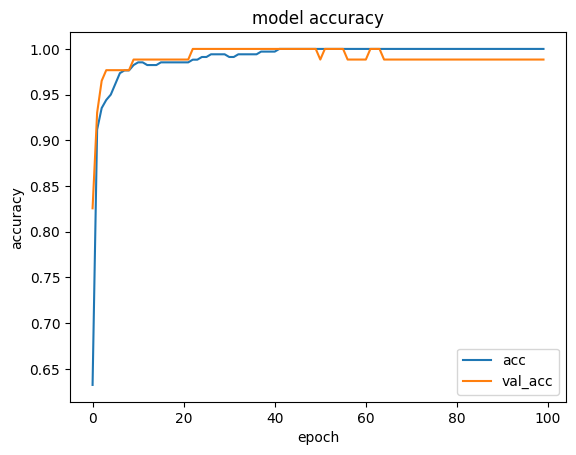

In [ ]:
plt.plot(history.history['accuracy'], label = "acc")
plt.plot(history.history['val_accuracy'], label = "val_acc")
plt.xlabel('epoch')
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.legend()

# **Multi class (iris)**

In [ ]:
from sklearn.datasets import load_iris

In [ ]:
iris = load_iris()
x, y = iris.data, iris.target

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y,
                                                    random_state= 42,
                                                    test_size = 0.25)

In [ ]:
sca = StandardScaler()
x_train = sca.fit_transform(x_train)
x_test = sca.transform(x_test)

In [ ]:
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [ ]:
from tensorflow.keras.utils import to_categorical

In [ ]:
# to categorical

y_train = to_categorical(y_train)
y_test = to_categorical(y_test)

In [ ]:
y_train;

In [ ]:
x_train.shape[1]

4

In [ ]:
multi_model = Sequential()
multi_model.add(Dense(64, activation = 'relu',
                input_shape = (x_train.shape[1],)))
multi_model.add(Dense(32, activation = 'relu'))
multi_model.add(Dense(3, activation = 'softmax'))

In [ ]:
# compile

multi_model.compile(optimizer = 'adam',
              loss = 'categorical_crossentropy',
              metrics = ['accuracy'])

In [ ]:
multi_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                 │ (None, 64)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,499 (9.76 KB)

 Trainable params: 2,499 (9.76 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = multi_model.fit(x_train, y_train, epochs = 100,
                    validation_split = 0.2,
                    batch_size = 32)

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 605ms/step - accuracy: 0.2755 - loss: 1.1028 - val_accuracy: 0.3913 - val_loss: 0.9958
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.3763 - loss: 1.0408 - val_accuracy: 0.5652 - val_loss: 0.9344
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.6630 - loss: 0.9749 - val_accuracy: 0.6522 - val_loss: 0.8782
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.8029 - loss: 0.9098 - val_accuracy: 0.7391 - val_loss: 0.8261
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.8554 - loss: 0.8440 - val_accuracy: 0.7826 - val_loss: 0.7766
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.7929 - loss: 0.8008 - val_accuracy: 0.7826 - val_loss: 0.7317
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.8242 - loss: 0.7443 - val_accuracy: 0.7826 - val_loss: 0.6907
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.8342 - loss: 0.6970 - val_accuracy: 0.7826 - val_loss

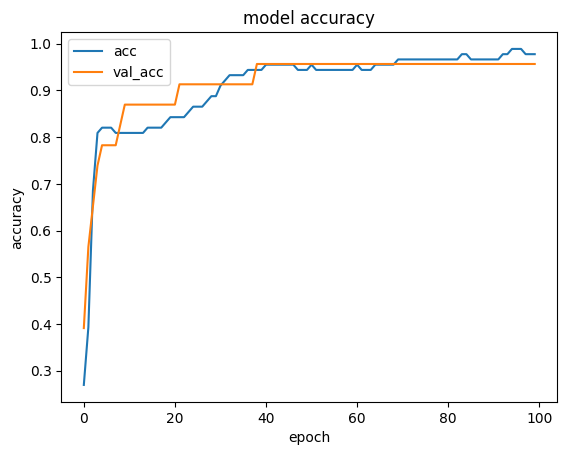

In [ ]:
plt.plot(history.history['accuracy'], label = "acc")
plt.plot(history.history['val_accuracy'], label = "val_acc")
plt.xlabel('epoch')
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.legend()